In [1]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np

## Data settings

In [2]:
colors = ["#8CBCEA", "#65C59A", "#e2d439", "#EC874C", "#EF8082", "#E094D7", "#D7AC63", "#AC9CF4", "#959C9E"]
conf_colors = colors[:2] + [colors[6]] + [colors[5]]
hdata_path = "../data/curated_data/3string_hobs.pkl"
shots = 300000
hfinal_time = 4.5
hdt = 0.15
tndata_probs_path = "../data/tn/3string/tnprobs.npy"
tndata_obs_path = "../data/tn/3string/tndata.txt"
tnfinal_time = 8
tndt = 0.01
tn_conf_indices = [0, 3, 1, 2]
occupied_qubits = [
    [2, 16, 22, 26],
    [2, 22, 26, 30],
    [2, 14, 22, 26],
    [2, 18, 22, 26],
]

plot_time = 3
hdata_limit = int(np.ceil(plot_time / hdt))+1
tn_data_limit = int(np.ceil(plot_time / tndt))+1

## Load data

In [3]:
import numpy as np
import pickle

with open(hdata_path, "rb") as f:
    data = pickle.load(f)
    hobs = data[0][0]
    hconf = data[1][0]
    hpsamples_sim = data[3][0][0]
    hpsamples_data = data[3][1][0]

observables_to_plot = np.load("../data/curated_data/3string_hcorrs.npy")[:hdata_limit, :]
observables_confidence = np.load("../data/curated_data/3string_hcorrs_conf.npy")[:hdata_limit, :]

tndata_probs = np.load(tndata_probs_path)
tndata_obs = np.loadtxt(tndata_obs_path)

## Auxiliary plot functions

In [4]:
def plot_individual_qubits_htn_comparison_to_ax(
    ax, 
    observable_matrix_hardware, 
    observable_matrix_tn, 
    qubit_indices, 
    observable_confidence_hardware=None, 
    x_ticks=None, 
    x_label=None,
    x_ticks_labels=None,
    y_label=None, 
    y_lim=None,
    y_ticks=None,
    labels=None, 
    markers=None,
    cmap=None, 
    title="", 
    legend=None
):
    observable_matrix_hardware = np.array(observable_matrix_hardware)[:, qubit_indices]
    observable_matrix_tn = np.array(observable_matrix_tn)[:, qubit_indices]
    if observable_confidence_hardware is not None:
        observable_confidence_hardware = np.array(observable_confidence_hardware)[:, qubit_indices, :]
        if observable_matrix_hardware.shape != observable_confidence_hardware.shape[:-1]:
            raise ValueError("Observable matrix and standard deviation matrix must have the same shape")
    
    if labels is not None:
        if len(labels) != observable_matrix_hardware.shape[1]:
            raise ValueError("labels must have the same length as number of observable")
        
    if markers is not None:
        if len(markers) != observable_matrix_hardware.shape[1]:
            raise ValueError("markers must have the same length as number of observable")
    else:
        markers = ["o"]*observable_matrix_hardware.shape[1]
    
    if cmap is None:
        cmap = plt.get_cmap("Set2")

    if x_ticks is not None:
        if len(x_ticks.shape) == 1:
            ax.set_xticks(x_ticks)
        else:
            ax.set_xticks(*x_ticks)
        x_hardware = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix_hardware.shape[0])
        x_tn = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix_tn.shape[0])
    else:
        x_hardware = np.arange(observable_matrix_hardware.shape[0])
        x_tn = np.arange(observable_matrix_tn.shape[0])

    if labels is None:
        labels = [f"$O_{i}$" for i in range(observable_matrix_hardware.shape[1])]

    hlines = []
    for i in reversed(range(observable_matrix_hardware.shape[1])):
        color = cmap((i % 8))
        ax.plot(x_tn, observable_matrix_tn[:, i], "-", markersize=10, markeredgecolor="black", color=color, label=labels[i], linewidth=3, zorder=2)
        yh = observable_matrix_hardware[:, i]
        if observable_confidence_hardware is not None:
            upper_error_bound_mask = np.less(yh.reshape((len(yh), 1)), observable_confidence_hardware[:, i, :])
            lower_error_bound_mask = np.greater(yh.reshape((len(yh), 1)), observable_confidence_hardware[:, i, :])
            consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
            upper_error = observable_confidence_hardware[:, i, 1][consistency_mask] - yh[consistency_mask]
            lower_error = yh[consistency_mask] - observable_confidence_hardware[:, i, 0][consistency_mask]
            yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
            yerr[consistency_mask, 0] = lower_error
            yerr[consistency_mask, 1] = upper_error
            ax.fill_between(x_hardware, observable_confidence_hardware[:, i, 0], observable_confidence_hardware[:, i, 1], color=cmap(i), alpha=0.3)
            hlines.append(ax.plot(x_hardware, observable_matrix_hardware[:, i], markers[i], markersize=8, markeredgecolor="black", color=color, label=labels[i], zorder=3))
        else:
            hlines.append(ax.plot(x_hardware, observable_matrix_hardware[:, i], markers[i], markersize=8, markeredgecolor="black", color=color, label=labels[i], zorder=3))
    
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label, labelpad=10)
    ax.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if y_lim == "data":
        min_data = np.nanmin(observable_matrix_hardware)
        max_data = np.nanmax(observable_matrix_hardware)
        ax.set_ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
    if x_ticks_labels is not None:
        ax.set_xticks(x_ticks)
        ax.set_xticklabels(x_ticks_labels)
    elif y_lim is not None:
        ax.set_ylim(y_lim)
    if y_ticks is not None:
        ax.set_yticks(y_ticks)
    if title:
        ax.set_title(title, pad=10, fontsize=26)
    if legend:
        ax.legend(handles=[ax.plot([], "o-", color=cmap(i % 8))[0] for i in range(observable_matrix_hardware.shape[1])], labels=[line[0].get_label() if isinstance(line, list) else line.get_label() for line in hlines], loc="upper right", fontsize=16)

def get_lims_from_ticks(ticks, relmargin, y_lim=None):
    if y_lim is not None:
        mask = np.logical_and(ticks >= y_lim[0], ticks <= y_lim[1])
        ticks = ticks[mask]
    min_tick = ticks[0]
    max_tick = ticks[-1]
    delta_ticks = max_tick - min_tick
    return [min_tick - relmargin * delta_ticks, max_tick + relmargin * delta_ticks]

def get_lims_from_ticks(ticks, relmargin, y_lim=None):
    if y_lim is not None:
        mask = np.logical_and(ticks >= y_lim[0], ticks <= y_lim[1])
        ticks = ticks[mask]
    min_tick = ticks[0]
    max_tick = ticks[-1]
    delta_ticks = max_tick - min_tick
    return [min_tick - relmargin * delta_ticks, max_tick + relmargin * delta_ticks]

## Plot

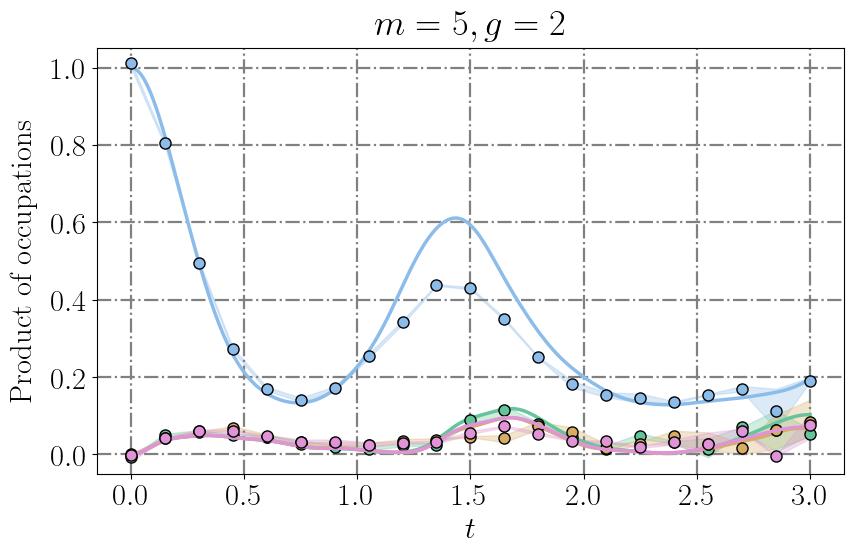

In [ ]:
from utils.observables import load_occupation_correlators_bypaulis
from utils.plotting import plot_individual_qubits_htn_comparison

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$t$"
y_label = r"Product of occupations"
y_lim = [-0.05, 1.05]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = r"$m = 5, g = 2$"
labels = None
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False

tn_data_to_plot = np.sqrt(tndata_probs[:tn_data_limit, tn_conf_indices])

plot_individual_qubits_htn_comparison(observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath="/results/correlators_large.svg")

In [6]:
observables_to_plot.shape

(21, 4)

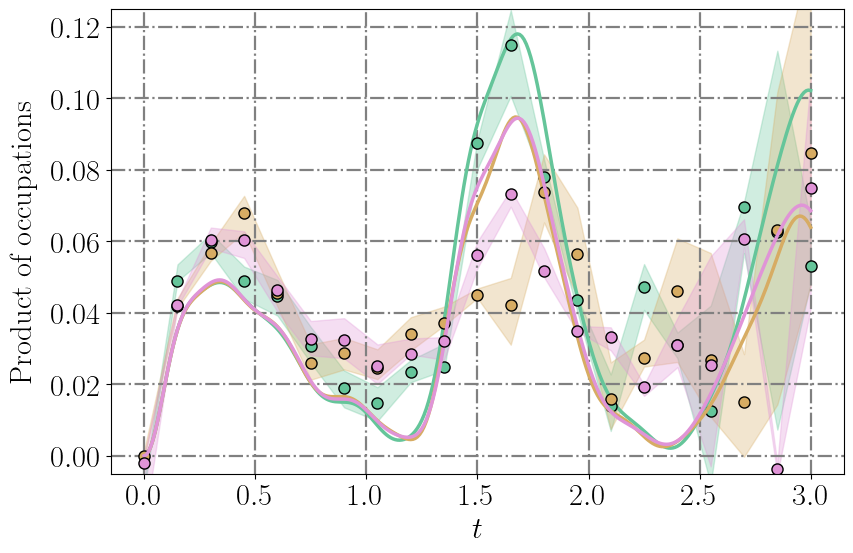

In [ ]:
from utils.observables import load_occupation_correlators_bypaulis
from utils.plotting import plot_individual_qubits_htn_comparison

x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$t$"
y_label = r"Product of occupations"
y_lim = [-0.005, 0.125]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = None
cmap = lambda x: conf_colors[x+1] if x < len(conf_colors) else "black"
legend = False

tn_data_to_plot = np.sqrt(tndata_probs[:tn_data_limit, tn_conf_indices])

plot_individual_qubits_htn_comparison(observables_to_plot[:, 1:], tn_data_to_plot[:, 1:], [0, 1, 2], observables_confidence[:, 1:, :], x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, cmap=cmap, title=title, legend=legend, filepath="/results/correlators_zoom.svg")

In [8]:
observables_to_plot[:,3]

array([-0.00194411,  0.04211104,  0.06039282,  0.06043194,  0.04649659,
        0.03256282,  0.03237954,  0.02505952,  0.02836938,  0.03214119,
        0.056154  ,  0.07328227,  0.05181639,  0.034971  ,  0.0332748 ,
        0.01928986,  0.0310257 ,  0.02539596,  0.06069882, -0.00382974,
        0.0749299 ])

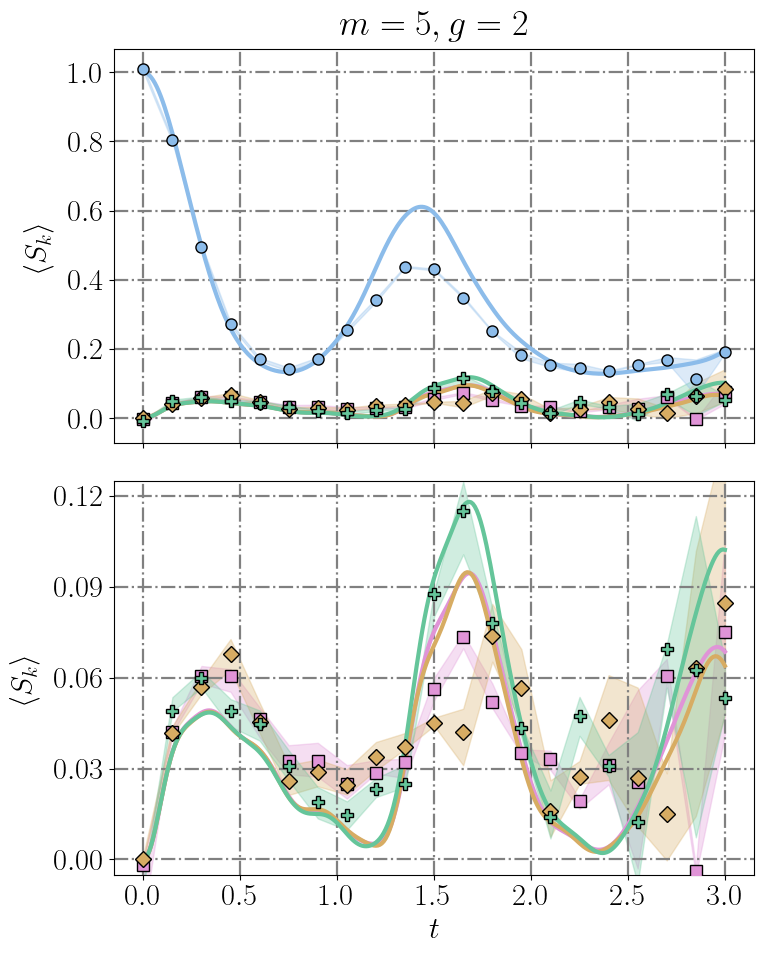

In [ ]:
plt.rc("text", usetex=True)
plt.rc("font", size=22, family="serif", weight="bold")

fig, axs = plt.subplots(2, 1, figsize=[8.1, 10], sharex=False)
plt.subplots_adjust(hspace=0.12)

# Row 0
x_ticks = np.linspace(0, plot_time, 7)
x_label = None #r"$t$"
y_label = r"$\langle S_k \rangle$"
y_lim = [-0.05, 1.05]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = r"$m = 5, g = 2$"
labels = None
cmap = lambda x: conf_colors[x] if x < len(conf_colors) else "black"
legend = False
x_ticks_labels = []
markers = ["o", "P", "D", "s"]

tn_data_to_plot = np.sqrt(tndata_probs[:tn_data_limit, tn_conf_indices])

plot_individual_qubits_htn_comparison_to_ax(axs[0], observables_to_plot, tn_data_to_plot, np.arange(observables_to_plot.shape[1]), observables_confidence, x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, labels=labels, markers=markers, cmap=cmap, x_ticks_labels=x_ticks_labels, title=title, legend=legend)

# Row 1
x_ticks = np.linspace(0, plot_time, 7)
x_label = r"$t$"
y_label = r"$\langle S_k \rangle$"
y_lim = [-0.005, 0.125]
# y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = None
labels = None
cmap = lambda x: conf_colors[x+1] if x < len(conf_colors) else "black"
legend = False
y_ticks = np.linspace(0, 0.12, 5)

tn_data_to_plot = np.sqrt(tndata_probs[:tn_data_limit, tn_conf_indices])

plot_individual_qubits_htn_comparison_to_ax(axs[1], observables_to_plot[:, 1:], tn_data_to_plot[:, 1:], [0, 1, 2], observables_confidence[:, 1:, :], x_ticks=x_ticks, x_label=x_label, y_label=y_label, y_lim=y_lim, y_ticks=y_ticks, labels=labels, markers=markers[1::], cmap=cmap, title=title, legend=legend)

plt.tight_layout()
plt.savefig("/results/correlators_together.svg")

## Legends

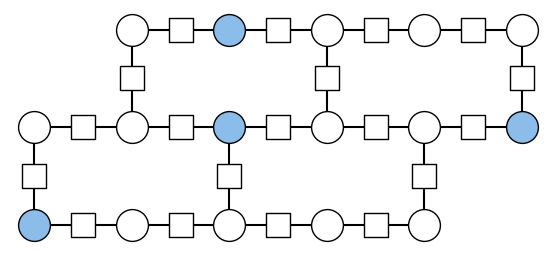

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2

conf_qubits = [2, 16, 22, 26]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(conf_qubits, colors=[conf_colors[0]]*len(conf_qubits), markers=["o"]*4, number_highlighted=False, filepath="/results/conf1_legend_python.svg", number_qubits=False)

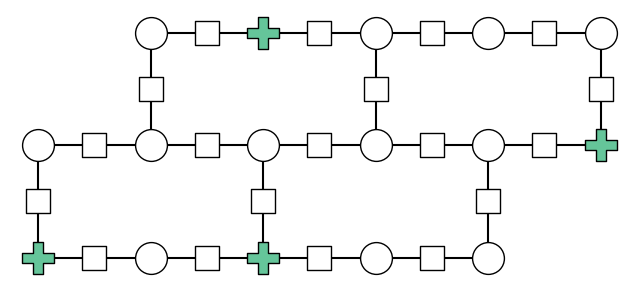

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2

conf_qubits = [2, 22, 26, 30]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(conf_qubits, colors=[conf_colors[1]]*len(conf_qubits), markers=["P"]*4, number_highlighted=False, filepath="/results/conf2_legend_python.svg", number_qubits=False)

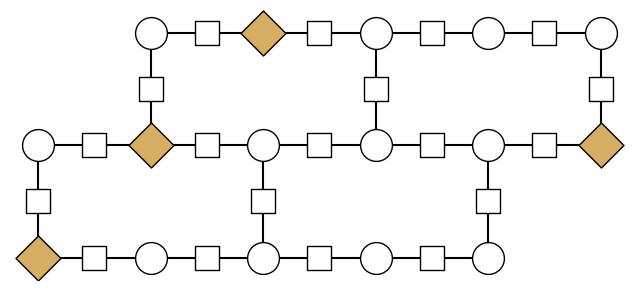

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2

conf_qubits = [2, 14, 22, 26]
markers = ["D"]*4

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(conf_qubits, colors=[conf_colors[2]]*len(conf_qubits), markers=markers, number_highlighted=False, filepath="/results/conf3_legend_python.svg", number_qubits=False)

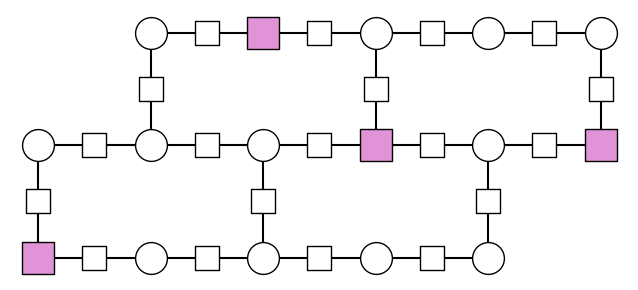

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2

conf_qubits = [2, 18, 22, 26]
markers = ["s"]*4

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(conf_qubits, colors=[conf_colors[3]]*len(conf_qubits), markers=markers, number_highlighted=False, filepath="/results/conf4_legend_python.svg", number_qubits=False)

## Appendix Figure

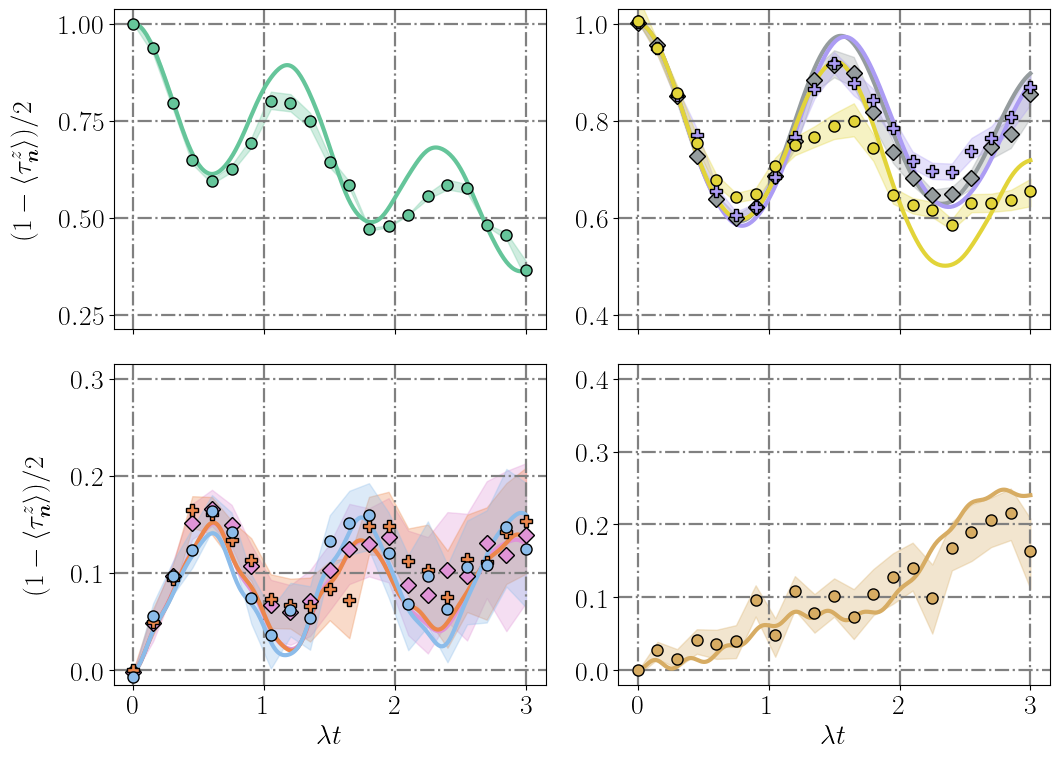

In [15]:
import matplotlib.pyplot as plt

# colors = ["#88B4DD", "#4E8988", "#56B389", "#8C8B5F", "#DC7C46", "#CD6B6E", "#CO7CB8", "#E1A132"]
colors = ["#8CBCEA", "#65C59A", "#e2d439", "#EC874C", "#EF8082", "#E094D7", "#D7AC63", "#AC9CF4", "#959C9E"]

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
plt.rc("text.latex", preamble=r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{bm}\usepackage{physics}")

fig, axs = plt.subplots(2, 2, figsize=(11, 8))

nxlabels = 4
margin = 0.05

# Col 1
cmap00 = lambda x: colors[1:][x] if x < len(colors[1:]) else "black"
qubit_indices00 = [16]
x_ticks00 = np.linspace(0, plot_time, 6)
y_lim00 = [0, 1]
title00 = None#r"$2 \times 2$ / $m = 5, g = 2$"
y_label00 = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
plot_individual_qubits_htn_comparison_to_ax(axs[0, 0], 
                                            (1-hobs[:hdata_limit])/2, (1-tndata_obs[:tn_data_limit, :])/2,
                                            # hobs[0], tnobs[0][:tn_data_limits[0], :],
                                            qubit_indices=qubit_indices00,
                                            observable_confidence_hardware=(1-hconf[:hdata_limit, :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[0],
                                            x_ticks=x_ticks00,
                                            x_label=None,
                                            y_label=r"$\langle n \rangle$",
                                            y_lim=y_lim00,
                                            cmap=cmap00,
                                            title=title00)
axs[0, 0].set_xticks(np.linspace(0, plot_time, nxlabels), [])
axs[0, 0].set_yticks(np.linspace(0.25, 1, 4))
axs[0, 0].set_ylabel(y_label00, labelpad=15)
axs[0, 0].set_ylim(get_lims_from_ticks(axs[0, 0].get_yticks(), margin, y_lim=y_lim00))

cmap10 = lambda x: [colors[0], colors[3], colors[5]][x] if x < len(colors[1:]) else "black"
qubit_indices10 = [30, 14, 18]
x_ticks10 = np.linspace(0, plot_time, 6)
y_lim10 = [0, 0.35]
title10 = None#r"$2 \times 2$ / $m = 5, g = 2$"
y_label10 = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
plot_individual_qubits_htn_comparison_to_ax(axs[1, 0], 
                                            (1-hobs[:hdata_limit])/2, (1-tndata_obs[:tn_data_limit, :])/2,
                                            # hobs[0], tnobs[0][:tn_data_limits[0], :],
                                            qubit_indices=qubit_indices10,
                                            observable_confidence_hardware=(1-hconf[:hdata_limit, :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[0],
                                            x_ticks=x_ticks10,
                                            x_label=r"$\lambda t$",
                                            y_label=r"$\langle n \rangle$",
                                            markers=["o", "P", "D"],
                                            y_lim=y_lim10,
                                            cmap=cmap10,
                                            title=title10)
axs[1, 0].set_xticks(np.linspace(0, plot_time, nxlabels))
axs[1, 0].set_yticks(np.linspace(0, 0.3, 4))
axs[1, 0].set_ylabel(y_label10, labelpad=15)
axs[1, 0].set_ylim(get_lims_from_ticks(axs[1, 0].get_yticks(), margin, y_lim=y_lim10))

# Col 2
cmap01 = lambda x: [colors[2], colors[-2], colors[-1]][x] if x < len(colors[1:]) else "black"
qubit_indices01 = [22, 2, 26]
x_ticks01 = np.linspace(0, plot_time, 6)
y_lim01 = [0.4, 1]
title01 = None#r"$2 \times 2$ / $m = 5, g = 2$"
y_label01 = None
plot_individual_qubits_htn_comparison_to_ax(axs[0, 1], 
                                            (1-hobs[:hdata_limit])/2, (1-tndata_obs[:tn_data_limit, :])/2,
                                            # hobs[0], tnobs[0][:tn_data_limits[0], :],
                                            qubit_indices=qubit_indices01,
                                            observable_confidence_hardware=(1-hconf[:hdata_limit, :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[0],
                                            x_ticks=x_ticks01,
                                            x_label=None,
                                            y_label=r"$\langle n \rangle$",
                                            y_lim=y_lim01,
                                            markers =["o", "P", "D"],
                                            cmap=cmap01,
                                            title=title01)
axs[0, 1].set_xticks(np.linspace(0, plot_time, nxlabels), [])
# axs[0, 1].set_yticks(np.linspace(0, 0.3, 4))
axs[0, 1].set_ylabel(y_label01, labelpad=15)
axs[0, 1].set_ylim(get_lims_from_ticks(axs[0, 1].get_yticks(), margin, y_lim=y_lim01))

cmap11 = lambda x: [colors[-3], colors[-2], colors[-1]][x] if x < len(colors[1:]) else "black"
qubit_indices11 = [34]
x_ticks11 = np.linspace(0, plot_time, 6)
y_lim11 = [0, 0.4]
title11 = None #r"$2 \times 2$ / $m = 5, g = 2$"
y_label11 = None
plot_individual_qubits_htn_comparison_to_ax(axs[1, 1], 
                                            (1-hobs[:hdata_limit])/2, (1-tndata_obs[:tn_data_limit, :])/2,
                                            # hobs[0], tnobs[0][:tn_data_limits[0], :],
                                            qubit_indices=qubit_indices11,
                                            observable_confidence_hardware=(1-hconf[:hdata_limit, :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[0],
                                            x_ticks=x_ticks11,
                                            x_label=r"$\lambda t$",
                                            y_label=r"$\langle n \rangle$",
                                            markers=["o"],
                                            y_lim=y_lim11,
                                            # markers=[""],
                                            cmap=cmap11,
                                            title=title11)
axs[1, 1].set_xticks(np.linspace(0, plot_time, nxlabels))
axs[1, 1].set_yticks(np.linspace(0, 0.4, 5))
axs[1, 1].set_ylabel(y_label11, labelpad=15)
axs[1, 1].set_ylim(get_lims_from_ticks(axs[1, 1].get_yticks(), margin, y_lim=y_lim11))

plt.tight_layout()
plt.savefig("supp_2string_occs_data.svg", facecolor="none")

## Legend

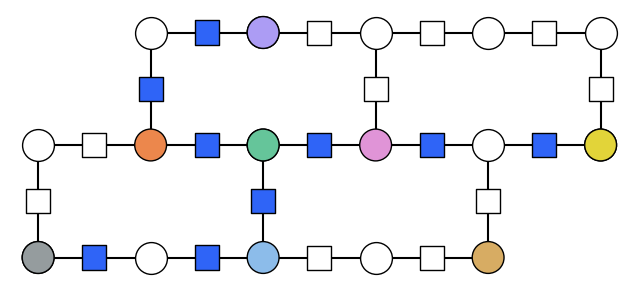

In [76]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2
highlighted_qubits = qubit_indices00 + qubit_indices01 + qubit_indices10 + qubit_indices11
legend_colors = [colors[1]] + [colors[2], colors[-2], colors[-1]] + [colors[0], colors[3], colors[5]] + [colors[-3]]#+ [colors[-3], colors[-2], colors[-1]]

string_qubits = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + legend_colors, number_highlighted=False, filepath=None, number_qubits=False)

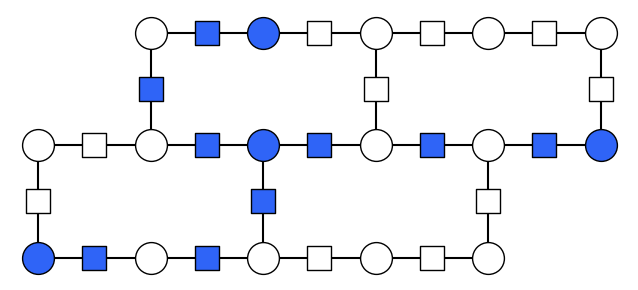

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2
highlighted_qubits = []
legend_colors = [colors[2], colors[-2], colors[-1]] + [colors[0], colors[3], colors[5]] + [colors[-3]]#+ [colors[-3], colors[-2], colors[-1]]

string_qubits = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]
markers = [(4, 0, 45), "o", (4, 0, 45), (4, 0, 45), (4, 0, 45), "o", (4, 0, 45), (4, 0, 45), "o", (4, 0, 45), "o", (4, 0, 45), (4, 0, 45)] + ["o", "P", "o", "P"]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + legend_colors, markers=markers, number_highlighted=False, filepath=None, number_qubits=False)

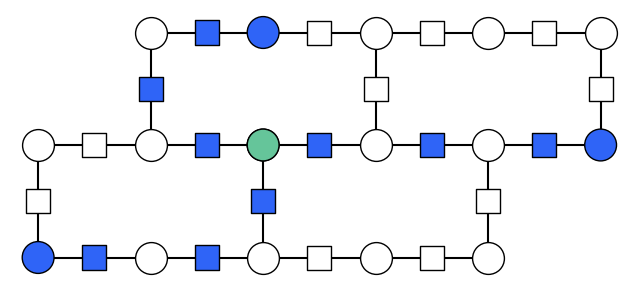

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2
highlighted_qubits = qubit_indices00 #+ qubit_indices01 + qubit_indices10 + qubit_indices11
legend_colors = [colors[1]] + [colors[2], colors[-2], colors[-1]] + [colors[0], colors[3], colors[5]] + [colors[-3]]#+ [colors[-3], colors[-2], colors[-1]]

string_qubits = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]
markers = ["o", (4, 0, 45), (4, 0, 45), (4, 0, 45), "o"] + ["o", "P", "o", "P", "s"]

# lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + legend_colors, number_highlighted=False, filepath="supp_2string_occs_legend_up_left.svg", number_qubits=False)

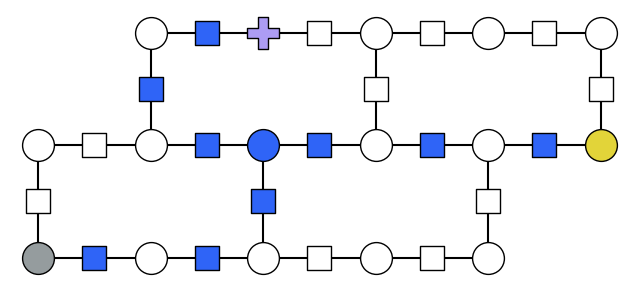

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2
highlighted_qubits = qubit_indices01 #+ qubit_indices10 + qubit_indices11
legend_colors = [colors[2], colors[-2], colors[-1]] + [colors[0], colors[3], colors[5]] + [colors[-3]] #+ [colors[-3], colors[-2], colors[-1]]

string_qubits = [1, 9, 15, 19, 16, 17, 21, 24, 27, 29]
markers = [(4, 0, 45), (4, 0, 45), (4, 0, 45), (4, 0, 45), "o", (4, 0, 45), (4, 0, 45), (4, 0, 45), (4, 0, 45), (4, 0, 45)] + ["o", "P", "o", "P"]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + legend_colors, markers=markers, number_highlighted=False, filepath="supp_2string_occs_legend_up_right.svg", number_qubits=False)

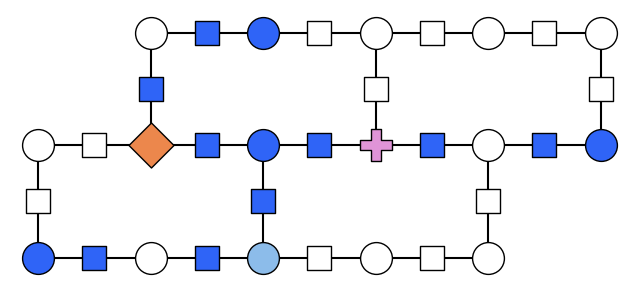

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2
highlighted_qubits = qubit_indices10
legend_colors = [colors[0], colors[3], colors[5]] + [colors[-3]] #+ [colors[-3], colors[-2], colors[-1]]

string_qubits = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]
markers = [(4, 0, 45), "o", (4, 0, 45), (4, 0, 45), (4, 0, 45), "o", (4, 0, 45), (4, 0, 45), "o", (4, 0, 45), "o", (4, 0, 45), (4, 0, 45)] + ["o", "D", "P"]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + legend_colors, markers=markers, number_highlighted=False, filepath="supp_2string_occs_legend_down_left.svg", number_qubits=False)

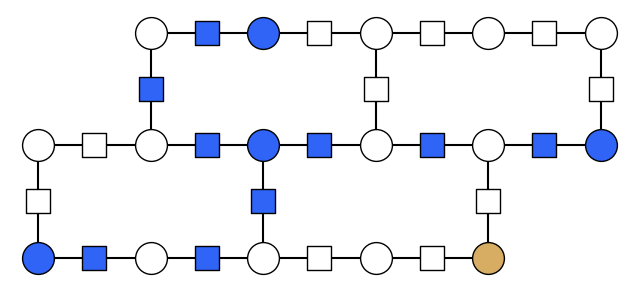

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2
highlighted_qubits = qubit_indices11
legend_colors = [colors[-3]]

string_qubits = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]
markers = [(4, 0, 45), "o", (4, 0, 45), (4, 0, 45), (4, 0, 45), "o", (4, 0, 45), (4, 0, 45), "o", (4, 0, 45), "o", (4, 0, 45), (4, 0, 45)] + ["o", "D", "P"]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + legend_colors, markers=markers, number_highlighted=False, filepath="supp_2string_occs_legend_down_right.svg", number_qubits=False)